In [1]:
#importing libraries
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.inspection import permutation_importance

In [2]:
#importing the dataset
df = pd.read_csv("breast-cancer-wisconsin.data", header=None)

In [3]:
#dataset information
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (699, 11)
Number of Rows: 699
Number of Columns: 11


In [4]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [5]:
#Reading the name file content using 'r' mode 
with open("breast-cancer-wisconsin.names", "r") as file:
    content = file.read()

print(content)

Citation Request:
   This breast cancer databases was obtained from the University of Wisconsin
   Hospitals, Madison from Dr. William H. Wolberg.  If you publish results
   when using this database, then please include this information in your
   acknowledgements.  Also, please cite one or more of:

   1. O. L. Mangasarian and W. H. Wolberg: "Cancer diagnosis via linear 
      programming", SIAM News, Volume 23, Number 5, September 1990, pp 1 & 18.

   2. William H. Wolberg and O.L. Mangasarian: "Multisurface method of 
      pattern separation for medical diagnosis applied to breast cytology", 
      Proceedings of the National Academy of Sciences, U.S.A., Volume 87, 
      December 1990, pp 9193-9196.

   3. O. L. Mangasarian, R. Setiono, and W.H. Wolberg: "Pattern recognition 
      via linear programming: Theory and application to medical diagnosis", 
      in: "Large-scale numerical optimization", Thomas F. Coleman and Yuying
      Li, editors, SIAM Publications, Philadelphia 199

In [6]:
#checking for the total number of missing values 

df.isnull().sum()

# there is none as the missing value is denoted in '?' 

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
dtype: int64

In [7]:
df[6].value_counts()
#checking the missing one '?' value count, found to be total of 16

6
1     402
10    132
2      30
5      30
3      28
8      21
4      19
?      16
9       9
7       8
6       4
Name: count, dtype: int64

In [8]:
#Assigning column names
columns = [
    "Sample_ID",
    "Clump_Thickness",
    "Uniformity_Cell_Size",
    "Uniformity_Cell_Shape",
    "Marginal_Adhesion",
    "Single_Epithelial_Cell_Size",
    "Bare_Nuclei",
    "Bland_Chromatin",
    "Normal_Nucleoli",
    "Mitoses",
    "Class"
]

df.columns = columns

In [9]:
df.head()

,Sample_ID,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Sample_ID                    699 non-null    int64
 1   Clump_Thickness              699 non-null    int64
 2   Uniformity_Cell_Size         699 non-null    int64
 3   Uniformity_Cell_Shape        699 non-null    int64
 4   Marginal_Adhesion            699 non-null    int64
 5   Single_Epithelial_Cell_Size  699 non-null    int64
 6   Bare_Nuclei                  699 non-null    str  
 7   Bland_Chromatin              699 non-null    int64
 8   Normal_Nucleoli              699 non-null    int64
 9   Mitoses                      699 non-null    int64
 10  Class                        699 non-null    int64
dtypes: int64(10), str(1)
memory usage: 60.2 KB


In [11]:
#Bare_Nuclei is stored as a string because of '?' can cause pandas issue so cnveer them to nummerical 

df["Bare_Nuclei"] = df["Bare_Nuclei"].replace("?", np.nan)

In [12]:
#convereting them to nummeric
df["Bare_Nuclei"] = pd.to_numeric(df["Bare_Nuclei"])

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_ID                    699 non-null    int64  
 1   Clump_Thickness              699 non-null    int64  
 2   Uniformity_Cell_Size         699 non-null    int64  
 3   Uniformity_Cell_Shape        699 non-null    int64  
 4   Marginal_Adhesion            699 non-null    int64  
 5   Single_Epithelial_Cell_Size  699 non-null    int64  
 6   Bare_Nuclei                  683 non-null    float64
 7   Bland_Chromatin              699 non-null    int64  
 8   Normal_Nucleoli              699 non-null    int64  
 9   Mitoses                      699 non-null    int64  
 10  Class                        699 non-null    int64  
dtypes: float64(1), int64(10)
memory usage: 60.2 KB


In [14]:
df.isnull().sum()

Sample_ID                       0
Clump_Thickness                 0
Uniformity_Cell_Size            0
Uniformity_Cell_Shape           0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    16
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

In [15]:
#checking for duplication 
df.duplicated().sum()

np.int64(8)

In [16]:
#checking if samplke id is repeated - becuase they might have different values byut same identifiers.
df["Sample_ID"].duplicated().sum()

np.int64(54)

In [17]:
df[df["Sample_ID"].duplicated(keep=False)].sort_values("Sample_ID")

,Sample_ID,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
267,320675,3,3,5,2,3,10.0,7,1,1,4
272,320675,3,3,5,2,3,10.0,7,1,1,4
269,385103,1,1,1,1,2,1.0,3,1,1,2
575,385103,5,1,2,1,2,1.0,3,1,1,2
607,411453,1,1,1,1,2,1.0,1,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...
560,1321942,5,1,1,1,2,1.0,3,1,1,2
661,1339781,4,1,1,1,2,1.0,3,1,1,2
660,1339781,1,1,1,1,2,1.0,2,1,1,2
673,1354840,5,3,2,1,3,1.0,1,1,1,2


In [18]:
#Exact duplicated rows is 8 and repeated data with different values (records) are 54
# Number of unique sample IDs
df["Sample_ID"].nunique()

645

In [19]:
# Number of rows belonging to repeated sample IDs
df["Sample_ID"].duplicated(keep=False).sum()

#100 is the number of rows belonging to repeated IDs, not the number of duplicate IDs.

np.int64(100)

In [20]:
# Number of repeated IDs that have conflicting measurements
duplicate_groups = df.groupby("Sample_ID")

conflicting_ids = []

for sample_id, group in duplicate_groups:

    unique_records = group.drop_duplicates()

    if len(unique_records) > 1:
        conflicting_ids.append(sample_id)

len(conflicting_ids)

39

In [21]:
#Data inspection task
#This is the target column

df["Class"].value_counts()

#2 = Benign,4 = Malignant

Class
2    458
4    241
Name: count, dtype: int64

In [22]:
df["Class"].value_counts(normalize=True) * 100

Class
2    65.522175
4    34.477825
Name: proportion, dtype: float64

In [23]:
feature_columns = [
    "Clump_Thickness",
    "Uniformity_Cell_Size",
    "Uniformity_Cell_Shape",
    "Marginal_Adhesion",
    "Single_Epithelial_Cell_Size",
    "Bare_Nuclei",
    "Bland_Chromatin",
    "Normal_Nucleoli",
    "Mitoses"
]

df[feature_columns].describe()

,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses
count,699.000000,699.000000,699.000000,699.000000,699.000000,683.000000,699.000000,699.000000,699.000000
mean,4.417740,3.134478,3.207439,2.806867,3.216023,3.544656,3.437768,2.866953,1.589413
std,2.815741,3.051459,2.971913,2.855379,2.214300,3.643857,2.438364,3.053634,1.715078
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000
50%,4.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,1.000000
75%,6.000000,5.000000,5.000000,4.000000,4.000000,6.000000,5.000000,4.000000,1.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [24]:
#Bare_Nuclei is missing 16 values
df[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Clump_Thickness,699.0,4.417740,2.815741,1.0,2.0,4.0,6.0,10.0
Uniformity_Cell_Size,699.0,3.134478,3.051459,1.0,1.0,1.0,5.0,10.0
Uniformity_Cell_Shape,699.0,3.207439,2.971913,1.0,1.0,1.0,5.0,10.0
Marginal_Adhesion,699.0,2.806867,2.855379,1.0,1.0,1.0,4.0,10.0
Single_Epithelial_Cell_Size,699.0,3.216023,2.214300,1.0,2.0,2.0,4.0,10.0
Bare_Nuclei,683.0,3.544656,3.643857,1.0,1.0,1.0,6.0,10.0
Bland_Chromatin,699.0,3.437768,2.438364,1.0,2.0,3.0,5.0,10.0
Normal_Nucleoli,699.0,2.866953,3.053634,1.0,1.0,1.0,4.0,10.0
Mitoses,699.0,1.589413,1.715078,1.0,1.0,1.0,1.0,10.0


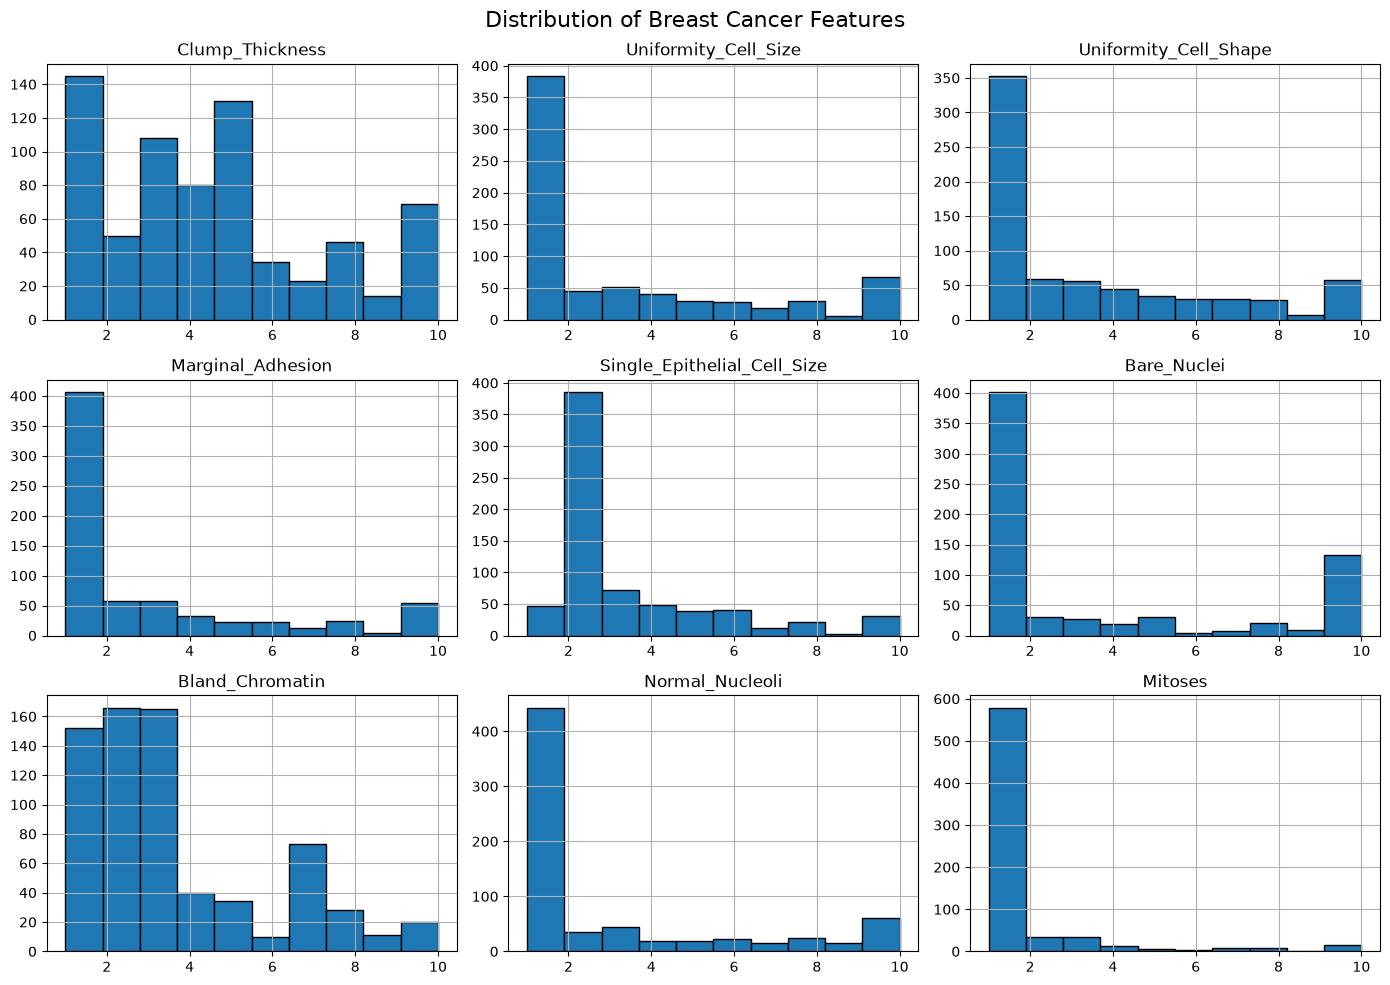

In [25]:
#Visualising feature distributions
df[feature_columns].hist(
    figsize=(14, 10),
    bins=10,
    edgecolor="black"
)

plt.suptitle("Distribution of Breast Cancer Features", fontsize=16)
plt.tight_layout()
plt.show()

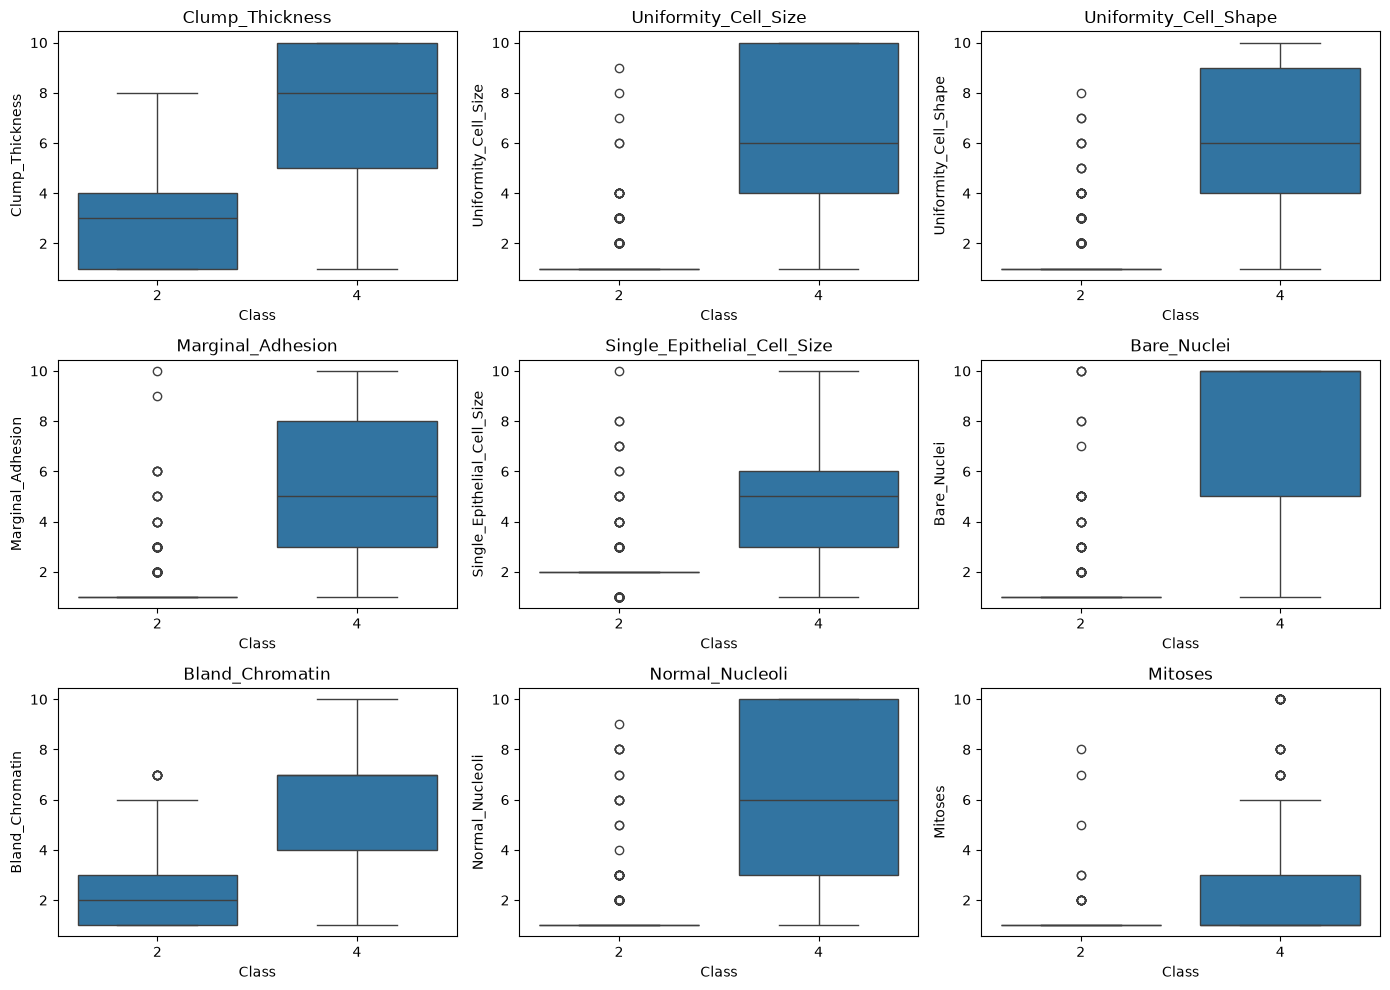

In [26]:
#relationship between features and diagnosis
plt.figure(figsize=(14, 10))

for i, feature in enumerate(feature_columns, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(
        data=df,
        x="Class",
        y=feature
    )

    plt.title(feature)

plt.tight_layout()
plt.show()

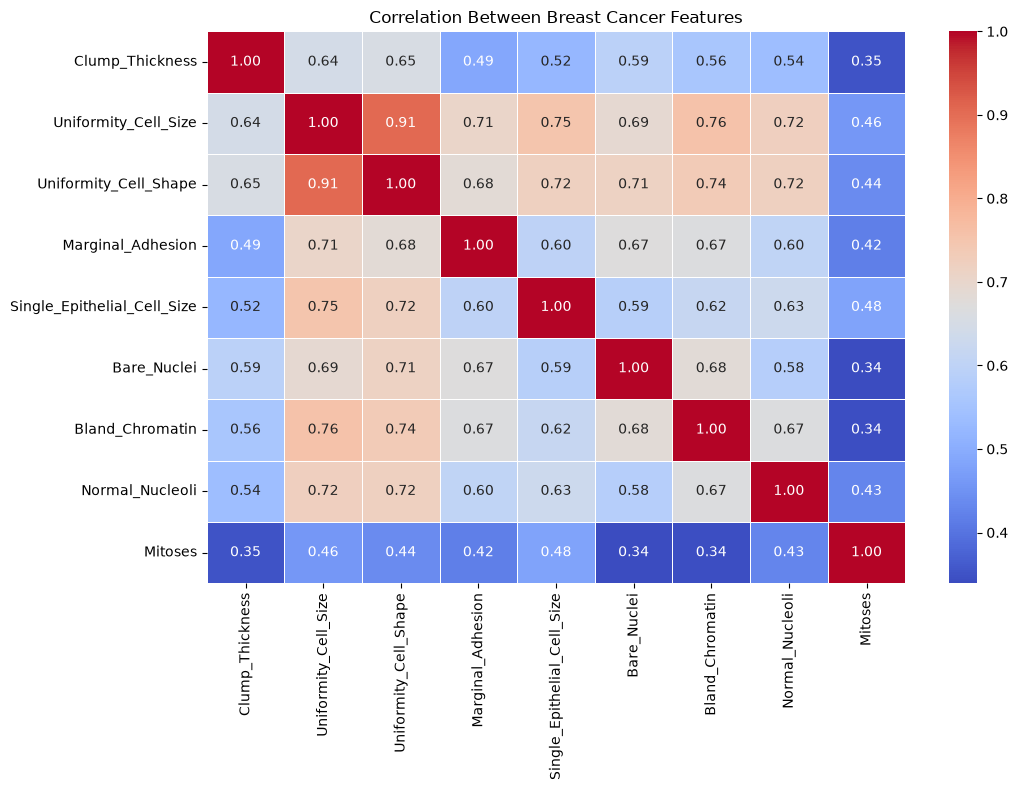

In [27]:
#In the above observation mitosis is seems to be less infomative because boht the class that it lies is less.

#heatmap to see the  correlation between features
correlation_matrix = df[feature_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Breast Cancer Features")
plt.tight_layout()
plt.show()

In [28]:
#check for repeated Sample_IDs have different class labels.
class_conflicts = df.groupby("Sample_ID")["Class"].nunique()

class_conflicts[class_conflicts > 1]

Sample_ID
695091     2
1171710    2
1198641    2
1299596    2
Name: Class, dtype: int64

In [29]:
conflicting_sample_ids = class_conflicts[class_conflicts > 1].index

df[df["Sample_ID"].isin(conflicting_sample_ids)].sort_values("Sample_ID").T

,577,691,109,108,258,266,168,467,644
Sample_ID,695091.0,695091.0,1171710.0,1171710.0,1198641.0,1198641.0,1198641.0,1299596.0,1299596.0
Clump_Thickness,1.0,5.0,6.0,1.0,3.0,10.0,3.0,6.0,2.0
Uniformity_Cell_Size,1.0,10.0,5.0,1.0,1.0,10.0,1.0,6.0,1.0
Uniformity_Cell_Shape,1.0,10.0,4.0,1.0,1.0,6.0,1.0,6.0,1.0
Marginal_Adhesion,1.0,5.0,4.0,1.0,1.0,3.0,1.0,5.0,1.0
Single_Epithelial_Cell_Size,2.0,4.0,3.0,2.0,2.0,3.0,2.0,4.0,2.0
Bare_Nuclei,1.0,5.0,9.0,1.0,1.0,10.0,1.0,10.0,1.0
Bland_Chromatin,2.0,4.0,7.0,2.0,3.0,4.0,3.0,7.0,1.0
Normal_Nucleoli,1.0,4.0,8.0,3.0,1.0,3.0,1.0,6.0,1.0
Mitoses,1.0,1.0,3.0,1.0,1.0,2.0,1.0,2.0,1.0


In [30]:
#As i don't know whether the repeated IDs represent repeated observations or an identifier issue,
#Removing them without understanding their origin could discard useful information.
#i cannot confidently decide which class label is correct using the dataset alone.
# So i will document these four conflicting IDs as an unresolved source-data inconsistency.

In [31]:
print("Original shape:", df.shape)

df_no_exact_duplicates = df.drop_duplicates()

print("Shape after removing exact duplicates:",
      df_no_exact_duplicates.shape)

print("Rows removed:",
      df.shape[0] - df_no_exact_duplicates.shape[0])


Original shape: (699, 11)
Shape after removing exact duplicates: (691, 11)
Rows removed: 8


# EDA

In [32]:
# Separate independent variables (x) and dependent variable (y)

X = df_no_exact_duplicates.drop(columns=["Sample_ID", "Class"])

y = df_no_exact_duplicates["Class"]

In [33]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)


print("\nTarget values:")
print(y.value_counts())

Features shape: (691, 9)
Target shape: (691,)

Target values:
Class
2    453
4    238
Name: count, dtype: int64


In [34]:
# Encode target variable

y = y.map({2: 0, 4: 1})
#2 - > benign 
#4 - > Malignant

In [35]:
print(y.value_counts())

print("\nUnique target values:", y.unique())

Class
0    453
1    238
Name: count, dtype: int64

Unique target values: [0 1]


In [36]:
# Check missing values in X

print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

Missing values in each feature:
Clump_Thickness                 0
Uniformity_Cell_Size            0
Uniformity_Cell_Shape           0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    16
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
dtype: int64

Total missing values: 16


In [37]:
#Handling the missing values using median imputation as the,value of mean lies between 1-10
#They are ornial so median will be less sensitive to the extreme values.

print("Median of Bare_Nuclei:", X["Bare_Nuclei"].median())

Median of Bare_Nuclei: 1.0


In [38]:
#handling the missing value using simpple imputer method with median as the stratergy 
imputer = SimpleImputer(strategy="median")

#i didnt imputed it previously on the entire dataset to prevent from data lekage, and will be Using standard scaler for feature scaling numerical features

print("Unique target values:", y.unique())

Unique target values: [0 1]


In [39]:
# Identify Sample_ID values that appear more than once

duplicate_ids = df_no_exact_duplicates[
    df_no_exact_duplicates["Sample_ID"].duplicated(keep=False)
]

print("Rows with repeated Sample_ID:", duplicate_ids.shape[0])

print("\nNumber of unique repeated IDs:",
      duplicate_ids["Sample_ID"].nunique())

Rows with repeated Sample_ID: 85

Number of unique repeated IDs: 39


In [40]:
#In this step i am going to inspect the four sample_ids with the conflicting class labels.
#to understand why same id have both class labels.

conflicting_id_list = conflicting_sample_ids

In [41]:
conflicting_records = df_no_exact_duplicates[
    df_no_exact_duplicates["Sample_ID"].isin(conflicting_id_list)
]

conflicting_records.sort_values("Sample_ID")

,Sample_ID,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
691,695091,5,10,10,5,4,5.0,4,4,1,4
577,695091,1,1,1,1,2,1.0,2,1,1,2
108,1171710,1,1,1,1,2,1.0,2,3,1,2
109,1171710,6,5,4,4,3,9.0,7,8,3,4
266,1198641,10,10,6,3,3,10.0,4,3,2,4
168,1198641,3,1,1,1,2,1.0,3,1,1,2
467,1299596,6,6,6,5,4,10.0,7,6,2,4
644,1299596,2,1,1,1,2,1.0,1,1,1,2


In [42]:
#Not just the class ,the feature values are also different in all, Two possibilities are :
#The repeated IDs represent different observationss.
#There is an inconsistency in the original dataset.

duplicate_feature_counts = (
    duplicate_ids.groupby("Sample_ID")
    [X.columns.tolist()]
    .apply(lambda group: group.drop_duplicates().shape[0])
)

print(duplicate_feature_counts)

Sample_ID
385103     2
411453     2
493452     2
560680     2
654546     2
695091     2
733639     2
734111     2
769612     2
798429     2
822829     2
897471     2
1017023    2
1033078    2
1061990    2
1070935    2
1105524    2
1114570    2
1115293    2
1116192    2
1143978    2
1158247    2
1168736    2
1171710    2
1173347    2
1174057    2
1182404    6
1198641    2
1212422    2
1238777    2
1240603    2
1276091    5
1277792    2
1293439    2
1299596    2
1299924    2
1320077    2
1339781    2
1354840    2
dtype: int64


In [43]:
#37 IDs have 2 different measurement patterns.

#1182404 has 6 different measurement patterns.

#1276091 has 5 different measurement patterns.

#The UCI documentation mentions:
# Group 1 originally contained 369 records, of which 2 were removed, leaving 367.
# Some records were corrected because of invalid values.
# Sample 1182404 had its value in field 8 changed from 0 to 1. 
# As i find 1182404 is one of the IDs appearing six times in our dataset.

#But the documentation does not explain why that ID appears six times or whether those records represent different patients or observations.

#Because of this i will document this as a data quality limitation of my project.

# Data splitting

In [44]:
from sklearn.model_selection import GroupShuffleSplit

# Splitting the dataset while keeping repeated Sample_IDs together

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df_no_exact_duplicates["Sample_ID"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

#GroupShuffleSplit is used because,divides entire groups, keeping each group together - this Data containing related observations
#Done to prevent potential data leakge due to repeated sample id's

In [45]:
X_train.isnull().sum()

Clump_Thickness                 0
Uniformity_Cell_Size            0
Uniformity_Cell_Shape           0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    11
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
dtype: int64

In [46]:
X_test.isnull().sum()


Clump_Thickness                0
Uniformity_Cell_Size           0
Uniformity_Cell_Shape          0
Marginal_Adhesion              0
Single_Epithelial_Cell_Size    0
Bare_Nuclei                    5
Bland_Chromatin                0
Normal_Nucleoli                0
Mitoses                        0
dtype: int64

In [47]:
X_train["Bare_Nuclei"] = X_train["Bare_Nuclei"].fillna(1.0)

In [48]:
X_test["Bare_Nuclei"] = X_test["Bare_Nuclei"].fillna(1.0)

In [49]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


# Feature Scaling

In [50]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [51]:
#Transforming the testing data
X_test_scaled = scaler.transform(X_test)

In [52]:
print("Mean:", X_train_scaled.mean(axis=0))
print("Standard deviation:", X_train_scaled.std(axis=0))

Mean: [ 5.13027246e-17  1.28256812e-17 -1.28256812e-17  0.00000000e+00
  2.56513623e-17 -2.56513623e-17  2.56513623e-17 -8.97797681e-17
 -1.28256812e-17]
Standard deviation: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [53]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(554, 9)
(137, 9)


# Baseline Model

In [54]:
#working with a dummy model first
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [55]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.66,0.34]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](9,)","['Clump_Thickness','Uniformity_Cell_Size','Uniformity_Cell_Shape',..., 'Bland_Chromatin','Normal_Nucleoli','Mitoses']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,9
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [56]:
y_pred_dummy = dummy_model.predict(X_test)

In [57]:
print(y_pred_dummy)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [58]:
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

print("Dummy Model Accuracy:", dummy_accuracy)

Dummy Model Accuracy: 0.6423357664233577


In [59]:
cm_dummy = confusion_matrix(y_test, y_pred_dummy)

print(cm_dummy)

[[88  0]
 [49  0]]


In [60]:
#True Positives: No malignant cases detected.

In [61]:
#model 2 --- Logistic Regression
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [62]:
y_pred_log = log_model.predict(X_test_scaled)
print(y_pred_log)

[0 1 0 0 0 0 0 0 0 1 0 0 1 0 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 0 0 1 1 1 1 0 1
 0 0 1 0 0 1 1 1 0 0 1 0 0 1 0 0 1 0 0 0 1 1 1 0 0 1 0 0 1 1 1 1 1 0 0 0 1
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1
 1 1 0 1 1 0 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 1 1 0 0 0]


In [63]:
log_accuracy = accuracy_score(y_test, y_pred_log)
log_precision = precision_score(y_test, y_pred_log)
log_recall = recall_score(y_test, y_pred_log)
log_f1 = f1_score(y_test, y_pred_log)

print("Accuracy:", log_accuracy)
print("Precision:", log_precision)
print("Recall:", log_recall)
print("F1 Score:", log_f1)

Accuracy: 0.948905109489051
Precision: 0.92
Recall: 0.9387755102040817
F1 Score: 0.9292929292929293


In [64]:
cm_log = confusion_matrix(y_test, y_pred_log)

print(cm_log)

[[84  4]
 [ 3 46]]


In [65]:
#model 3 -- SVM Using kernel trick
from sklearn.svm import SVC
svm_model = SVC(kernel="rbf", probability=True, random_state=42)

In [66]:
svm_model.fit(X_train_scaled, y_train)

C:\Users\sreej\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [67]:
y_pred_svm = svm_model.predict(X_test_scaled)
print(y_pred_svm)

[0 1 1 0 0 0 0 0 0 1 0 0 1 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 0 1 1 1 1 1 0 1
 0 0 1 0 0 1 1 1 0 0 1 0 0 1 0 0 1 0 0 0 1 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1
 1 1 0 1 1 0 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 1 1 0 0 0]


In [68]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)

Accuracy: 0.9562043795620438
Precision: 0.8909090909090909
Recall: 1.0
F1 Score: 0.9423076923076923


In [69]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

print(cm_svm)

[[82  6]
 [ 0 49]]


In [70]:
# Model 4 --Decision Tree
from sklearn.tree import DecisionTreeClassifier
tree_model = DecisionTreeClassifier(random_state=42)

In [71]:
tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [72]:
y_pred_tree = tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(y_test, y_pred_tree)
tree_recall = recall_score(y_test, y_pred_tree)
tree_f1 = f1_score(y_test, y_pred_tree)

print("Accuracy:", tree_accuracy)
print("Precision:", tree_precision)
print("Recall:", tree_recall)
print("F1 Score:", tree_f1)

Accuracy: 0.9343065693430657
Precision: 0.8703703703703703
Recall: 0.9591836734693877
F1 Score: 0.912621359223301


In [73]:
#Model 5 -- Random Forest
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [74]:
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [75]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

Accuracy: 0.9635036496350365
Precision: 0.9230769230769231
Recall: 0.9795918367346939
F1 Score: 0.9504950495049505


In [76]:
#Model 6 -- Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier
gb_model = GradientBoostingClassifier(random_state=42)

In [77]:
gb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [78]:
y_pred_gb = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb)
gb_recall = recall_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)

print("Accuracy:", gb_accuracy)
print("Precision:", gb_precision)
print("Recall:", gb_recall)
print("F1 Score:", gb_f1)

Accuracy: 0.9416058394160584
Precision: 0.9019607843137255
Recall: 0.9387755102040817
F1 Score: 0.92


In [79]:
#comparing the resullt of all models 
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        0.9489, 0.9562, 0.9343, 0.9635, 0.9416
    ],
    "Precision": [
        0.9200, 0.8909, 0.8704, 0.9231, 0.9020
    ],
    "Recall": [
        0.9388, 1.0000, 0.9592, 0.9796, 0.9388
    ],
    "F1_Score": [
        0.9293, 0.9423, 0.9126, 0.9505, 0.9200
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.9489,0.9200,0.9388,0.9293
1,SVM,0.9562,0.8909,1.0000,0.9423
2,Decision Tree,0.9343,0.8704,0.9592,0.9126
3,Random Forest,0.9635,0.9231,0.9796,0.9505
4,Gradient Boosting,0.9416,0.9020,0.9388,0.9200


In [80]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [81]:
#Cross Validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

groups = df_no_exact_duplicates.loc[X_train.index, "Sample_ID"]

In [82]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=42))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=100, random_state=42))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=42))
    ])
}

In [83]:

scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]
cv_results = []

for name, pipeline in models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        groups=groups
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

cv_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9639,0.9619,0.9312,0.9462,0.9951
1,SVM,0.9765,0.9634,0.9683,0.9658,0.9924
2,Decision Tree,0.9440,0.9498,0.8835,0.9151,0.9294
3,Random Forest,0.9693,0.9530,0.9578,0.9550,0.9914
4,Gradient Boosting,0.9639,0.9483,0.9471,0.9473,0.9907


In [84]:
#New results: Each model was trained and evaluated across five different folds of the training data

# hyperparameter

In [85]:
from sklearn.model_selection import GridSearchCV

In [86]:
#Selecting SVM as it provided the best result,RF also provided good result.
svm_params = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto"]
}

In [87]:
svm_grid = GridSearchCV(
    estimator=models["SVM"],
    param_grid=svm_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [88]:
svm_grid.fit(X_train, y_train, groups=groups)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.1, 1, ...], 'model__gamma': ['scale', 'auto'], 'model__kernel': ['linear', 'rbf', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_au

In [89]:
print("Best parameters:", svm_grid.best_params_)
print("Best CV F1 score:", svm_grid.best_score_)

Best parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV F1 score: 0.9657516518569149


In [90]:
#The tuned configuration has the same F1 score as my original SVM score (96.58%).
#This shows tuning did not improve the CV F1, but it confirmed that my original configuration was already a strong choice.

In [91]:
best_svm = svm_grid.best_estimator_
y_pred_svm_tuned = best_svm.predict(X_test)

In [92]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm_tuned))
print("Precision:", precision_score(y_test, y_pred_svm_tuned))
print("Recall:", recall_score(y_test, y_pred_svm_tuned))
print("F1 Score:", f1_score(y_test, y_pred_svm_tuned))

Accuracy: 0.9562043795620438
Precision: 0.8909090909090909
Recall: 1.0
F1 Score: 0.9423076923076923


In [93]:
#Tuning Rf
rf_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

In [94]:
rf_grid = GridSearchCV(
    estimator=models["Random Forest"],
    param_grid=rf_params,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [95]:
rf_grid.fit(X_train, y_train, groups=groups)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more

In [96]:
print("Best parameters:", rf_grid.best_params_)
print("Best CV F1 score:", rf_grid.best_score_)

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10, 'model__n_estimators': 300}
Best CV F1 score: 0.9634259074259074


In [97]:
best_rf = rf_grid.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)

In [98]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print("Precision:", precision_score(y_test, y_pred_rf_tuned))
print("Recall:", recall_score(y_test, y_pred_rf_tuned))
print("F1 Score:", f1_score(y_test, y_pred_rf_tuned))

Accuracy: 0.9635036496350365
Precision: 0.9230769230769231
Recall: 0.9795918367346939
F1 Score: 0.9504950495049505


In [99]:
cm_svm = confusion_matrix(y_test, y_pred_svm_tuned)
cm_rf = confusion_matrix(y_test, y_pred_rf_tuned)

print("SVM Confusion Matrix:")
print(cm_svm)

print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

SVM Confusion Matrix:
[[82  6]
 [ 0 49]]

Random Forest Confusion Matrix:
[[84  4]
 [ 1 48]]


In [100]:
svm_probs = best_svm.predict_proba(X_test)[:, 1]
rf_probs = best_rf.predict_proba(X_test)[:, 1]

In [101]:
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

auc_svm = roc_auc_score(y_test, svm_probs)
auc_rf = roc_auc_score(y_test, rf_probs)

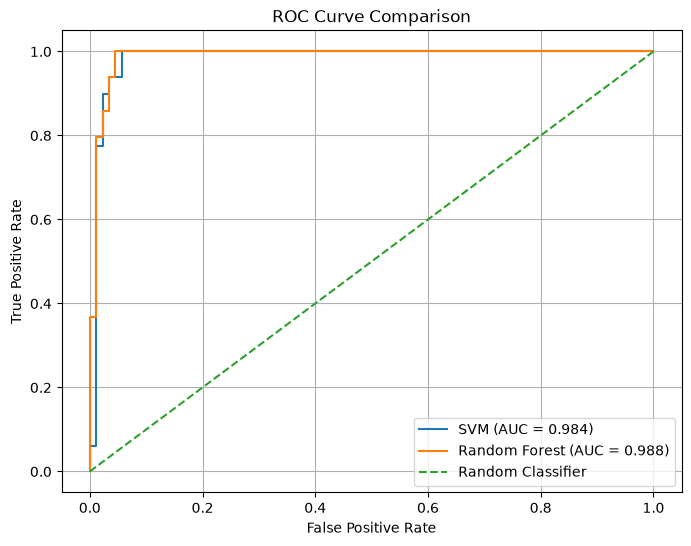

In [102]:
plt.figure(figsize=(8, 6))

plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {auc_svm:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

In [103]:
#Random Forest is currently the stronger overall, while SVM has the advantage of zero false negatives on this particular test set
rf_importance = permutation_importance(
    best_rf,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

In [104]:
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_importance.importances_mean,
    "Std": rf_importance.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance,Std
5,Bare_Nuclei,0.034263,0.013565
2,Uniformity_Cell_Shape,0.018539,0.008320
1,Uniformity_Cell_Size,0.012826,0.015362
6,Bland_Chromatin,0.005496,0.010883
3,Marginal_Adhesion,0.002796,0.004270
7,Normal_Nucleoli,0.002689,0.006814
0,Clump_Thickness,0.002488,0.008100
4,Single_Epithelial_Cell_Size,0.000000,0.000000
8,Mitoses,0.000000,0.000000


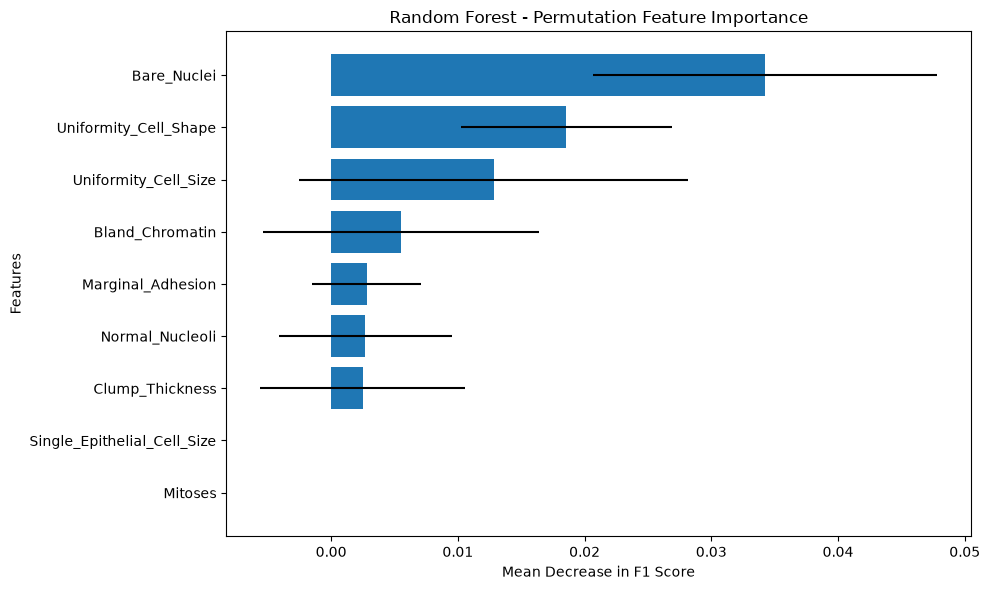

In [105]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    xerr=feature_importance["Std"]
)

plt.xlabel("Mean Decrease in F1 Score")
plt.ylabel("Features")
plt.title("Random Forest - Permutation Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [106]:
import shap

In [107]:
rf_model = best_rf.named_steps["model"]

In [108]:
X_test_imputed = best_rf.named_steps["imputer"].transform(X_test)

In [112]:
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test_imputed)
shap_malignant = shap_values.values[:, :, 1]

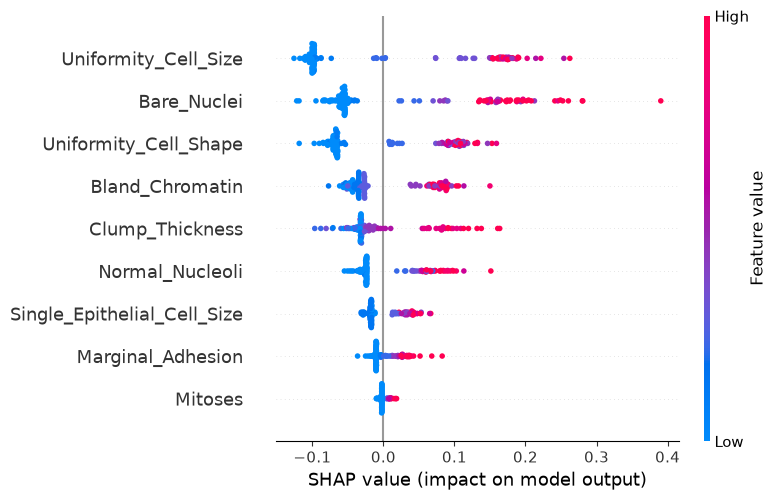

In [114]:
shap.summary_plot(
    shap_malignant,
    X_test_imputed,
    feature_names=list(X_test.columns)
)

In [115]:
malignant_indices = np.where(y_pred_rf_tuned == 1)[0]

sample_index = malignant_indices[0]

print("Test sample index:", sample_index)
print("Actual class:", y_test.iloc[sample_index])
print("Predicted class:", y_pred_rf_tuned[sample_index])

Test sample index: 1
Actual class: 0
Predicted class: 1


In [116]:
shap_exp = shap.Explanation(
    values=shap_malignant,
    base_values=explainer.expected_value[1],
    data=X_test_imputed,
    feature_names=list(X_test.columns)
)

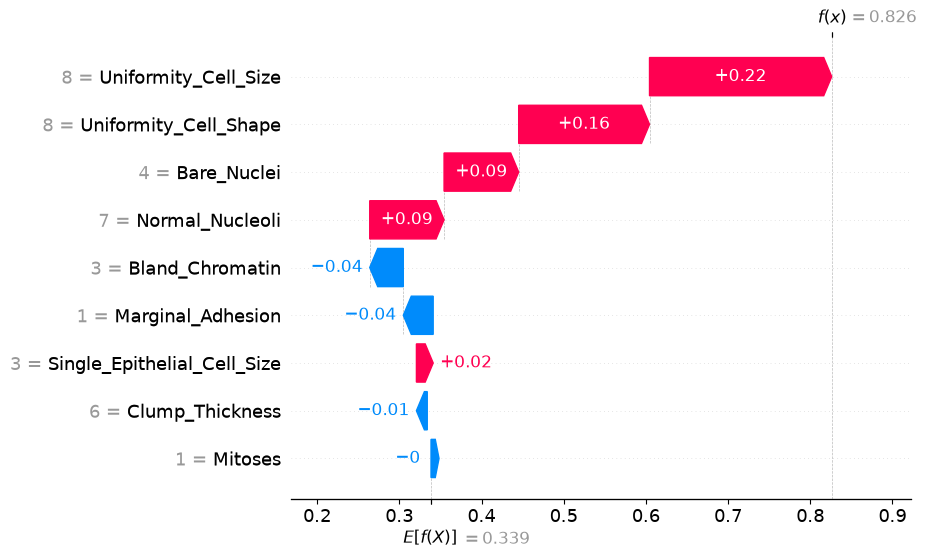

In [117]:
shap.plots.waterfall(shap_exp[sample_index])

In [ ]:
 # Saving the Final Model Pipeline using JobLib

In [118]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

model_path = "../models/random_forest_pipeline.joblib"

joblib.dump(best_rf, model_path)

print("Model pipeline saved successfully!")

Model pipeline saved successfully!
